# MVMD on real EEG: finding the alpha rhythm

When we close our eyes, the back of the brain produces the **alpha rhythm**, around 10 Hz. In a raw EEG recording it is mixed with slower waves, faster rhythms and noise. Here we use `mvmd` to separate them, on 8 channels at once.

**Data:** the [EEG Motor Movement/Imagery Dataset](https://physionet.org/content/eegmmidb/1.0.0/) of PhysioNet (G. Schalk et al., *BCI2000: a general-purpose brain-computer interface system*, IEEE Trans. Biomed. Eng., 2004), licence ODC-By 1.0. We use the 1-minute baseline of subject 1 with **eyes closed** (run 2), recorded at 160 Hz. [MNE-Python](https://mne.tools) downloads it (about 2.5 MB):

```sh
pip install mne
```

In [ ]:
import matplotlib.pyplot as plt
import mne
import numpy as np
import torch
from mne.datasets import eegbci
from scipy.signal import welch

from mvmd_torch import mvmd

mne.set_log_level("ERROR")

## 1. Load 8 channels over the back of the head

We keep the occipital and parieto-occipital channels, where alpha is strongest, remove the very slow drifts and the 60 Hz power-line noise, and standardise each channel (z-score) so that they all have the same weight.

In [ ]:
files = eegbci.load_data(1, [2], update_path=False)       # subject 1, run 2: eyes closed
raw = mne.io.read_raw_edf(files[0], preload=True)
eegbci.standardize(raw)                                     # standard channel names
channels = ["O1", "Oz", "O2", "PO7", "PO3", "POz", "PO4", "PO8"]
raw.pick(channels).filter(1.0, 70.0).notch_filter(60.0)
fs = raw.info["sfreq"]

data = raw.get_data()[:, : int(20 * fs)]                    # the first 20 seconds
x = (data - data.mean(axis=1, keepdims=True)) / data.std(axis=1, keepdims=True)
print("signal: ", x.shape, "(channels, samples) at", fs, "Hz")

signal:  (8, 3200) (channels, samples) at 160.0 Hz


## 2. Decompose into 5 modes

In [ ]:
u, _, omega = mvmd(torch.tensor(x, dtype=torch.float32), alpha=2000, tau=0, K=5, DC=False, init=1, tol=1e-7, max_N=500)
u = u.cpu().numpy()
centre = omega.real.cpu().numpy().ravel() * fs              # centre frequencies in Hz
order = np.argsort(centre)
u, centre = u[order], centre[order]
print("centre frequencies (Hz):", centre.round(1))

centre frequencies (Hz): [ 1.8 10.4 16.4 20.3 29.9]


## 3. Look at the modes

Rows: the raw signal, then the 5 modes. Columns: 3 channels (O1, Oz, O2) over 4 seconds, and on the right the spectrum averaged over the 8 channels (in grey, the spectrum of the raw signal).

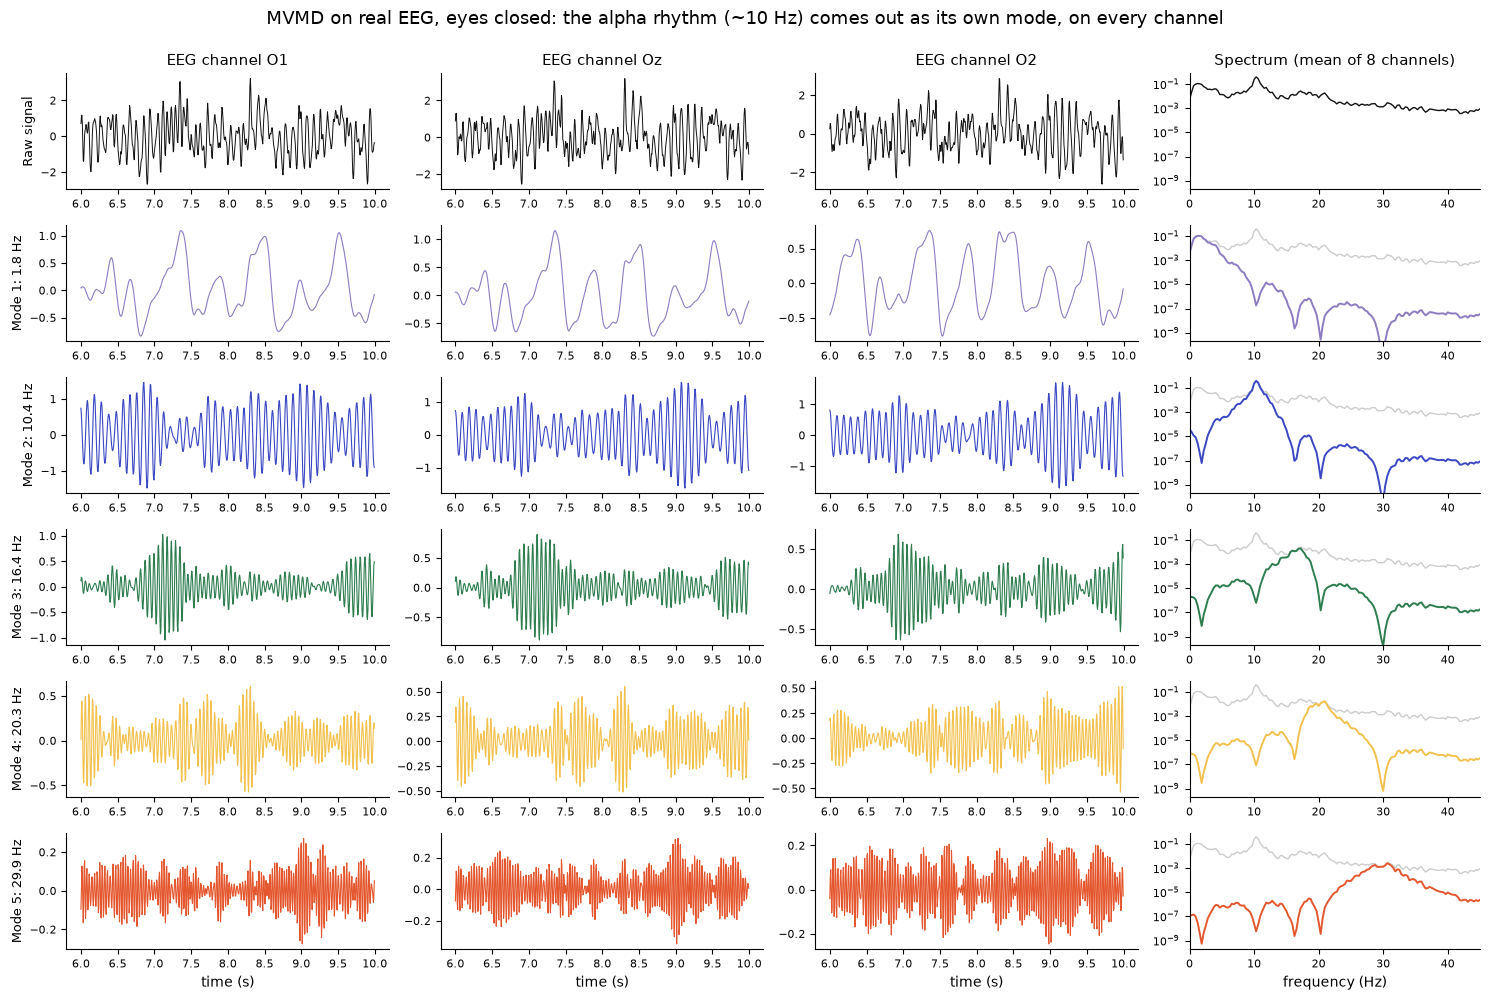

In [ ]:
show = [0, 1, 2]                                  # O1, Oz, O2
t0, t1 = int(6 * fs), int(10 * fs)                 # a 4-second window
t = np.arange(t0, t1) / fs
colors = ["#8E7CC3", "#3B47C4", "#2E7D4F", "#F2C14E", "#E4572E"]
names = [f"Mode {k + 1}: {centre[k]:.1f} Hz" for k in range(5)]

fig, axes = plt.subplots(6, 4, figsize=(15, 10), gridspec_kw={"width_ratios": [1, 1, 1, 0.9]})
for col, c in enumerate(show):
    axes[0, col].plot(t, x[c, t0:t1], color="#111111", lw=0.7)
    axes[0, col].set_title(f"EEG channel {channels[c]}", fontsize=11)
    for k in range(5):
        axes[k + 1, col].plot(t, u[k, t0:t1, c], color=colors[k], lw=0.8)
for k in range(5):
    axes[k + 1, 0].set_ylabel(names[k], fontsize=9)
axes[0, 0].set_ylabel("Raw signal", fontsize=9)
for ax in axes[-1, :3]:
    ax.set_xlabel("time (s)")

# right column: spectrum of the raw signal and of each mode, averaged over the 8 channels
f, p_raw = welch(x, fs=fs, nperseg=512)
axes[0, 3].semilogy(f, p_raw.mean(axis=0), color="#111111", lw=1)
axes[0, 3].set_title("Spectrum (mean of 8 channels)", fontsize=11)
axes[0, 3].set_ylim(p_raw.mean(axis=0).min() / 10, p_raw.mean(axis=0).max() * 2)
for k in range(5):
    _, p = welch(u[k].T, fs=fs, nperseg=512)
    axes[k + 1, 3].semilogy(f, p_raw.mean(axis=0), color="#CCCCCC", lw=1)
    axes[k + 1, 3].semilogy(f, p.mean(axis=0), color=colors[k], lw=1.4)
    axes[k + 1, 3].set_ylim(p_raw.mean(axis=0).min() / 10, p_raw.mean(axis=0).max() * 2)
for ax in axes[:, 3]:
    ax.set_xlim(0, 45)
axes[-1, 3].set_xlabel("frequency (Hz)")
for ax in axes.flat:
    ax.tick_params(labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("MVMD on real EEG, eyes closed: the alpha rhythm (~10 Hz) comes out as its own mode, on every channel",
             fontsize=13, y=0.995)
plt.tight_layout()
plt.show()

**What this shows:**

- The raw signal looks like noise, but its spectrum has a clear peak around 10 Hz.
- **Mode 2 (about 10 Hz) is the alpha rhythm**: a steady oscillation on every channel, whose spectrum sits exactly on the alpha peak.
- Modes 3 and 4 (about 16 and 20 Hz, the beta band) come in **bursts**: short periods of strong activity, invisible in the raw signal.
- Mode 1 holds the slow waves, and mode 5 the faster activity around 30 Hz.

Because the decomposition is multivariate, **mode 2 is the same rhythm on all channels**: we can compare its amplitude from one channel to another, or study how it changes in time, without filtering each channel by hand.